In [3]:
import pandas as pd
from sklearn.datasets import load_wine

# --- 1. DATASET LOADING ---
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)

# Target variable (preserving original indices)
y = pd.Series(data.target, name='target', index=X.index)

print("Feature Names (First 5):", data.feature_names[:5])
print("Target Classes / Names:", data.target_names)
print("\nClass Counts:\n", y.value_counts().sort_index().to_string())
print("\nDataset Shape:", X.shape)
display(X.head())

Feature Names (First 5): ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium']
Target Classes / Names: ['class_0' 'class_1' 'class_2']

Class Counts:
 target
0    59
1    71
2    48

Dataset Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Section 1: Dataset Loading
The Wine Classification dataset was successfully loaded using `scikit-learn`. It consists of 178 samples and 13 numerical features. The target variable was converted into a Pandas Series, perfectly preserving the original row indices. The target classes are 0, 1, and 2, representing three different cultivars.

Missing Values Per Column:
 alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0

Duplicate Full Rows: 0

Data Types Per Column:
 alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
p

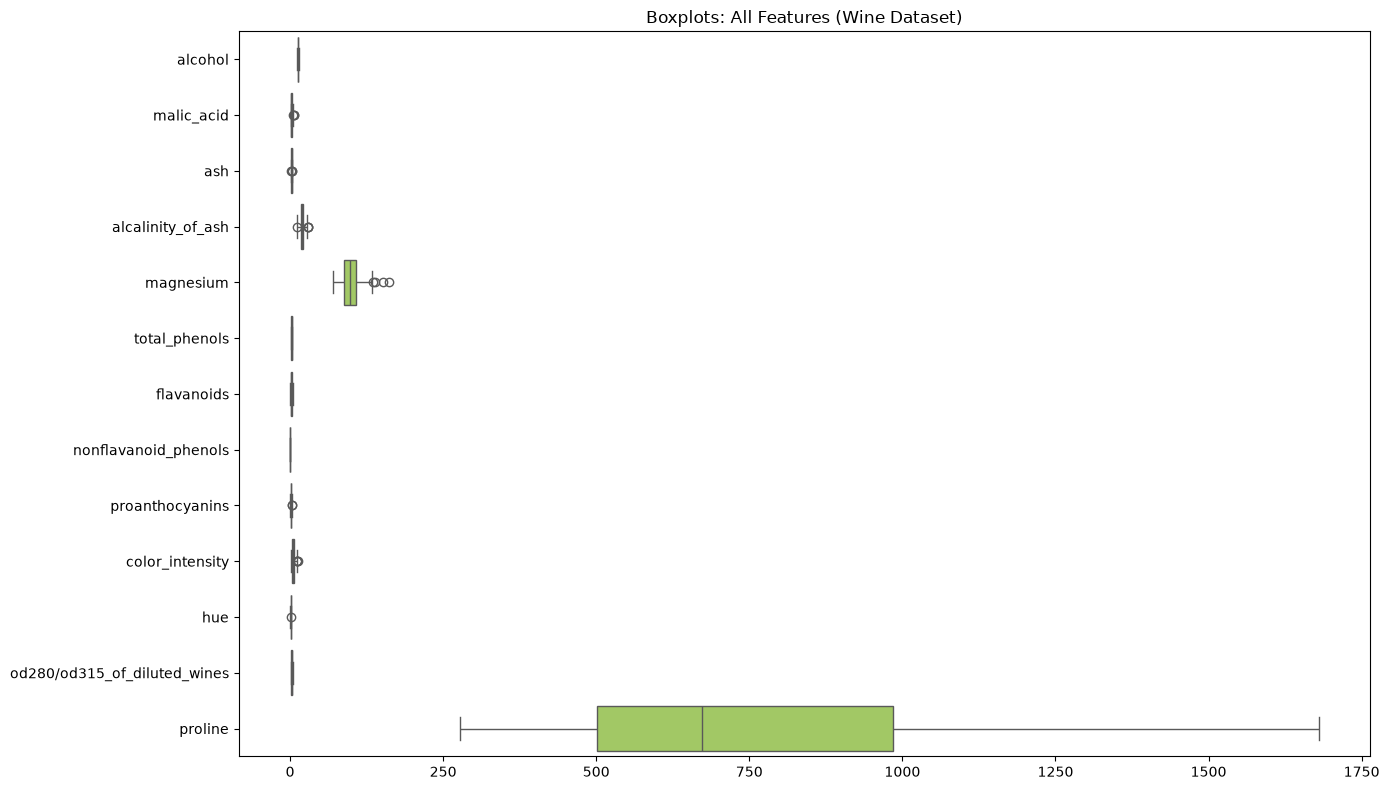

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 2. DATA QUALITY CHECKS ---
print("Missing Values Per Column:\n", X.isnull().sum().to_string())

# Check for full-row duplicates by temporarily combining X and y
full_df = X.copy()
full_df['target'] = y
print("\nDuplicate Full Rows:", full_df.duplicated().sum())

print("\nData Types Per Column:\n", X.dtypes.to_string())

# Boxplots for Wine features (all 13 numerical features)
plt.figure(figsize=(14, 8))
sns.boxplot(data=X, orient="h", palette="Set2")
plt.title("Boxplots: All Features (Wine Dataset)")
plt.tight_layout()
plt.show()

### Section 2: Data Quality Checks
Column-wise data quality checks confirm 0 missing values across all columns and 0 fully duplicated rows. All 13 features are numerical (float64). Boxplots reveal some potential outliers in features like `proline` and `malic_acid`, which reflect natural chemical variations among wine samples and are retained for modeling.

Descriptive Statistics:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


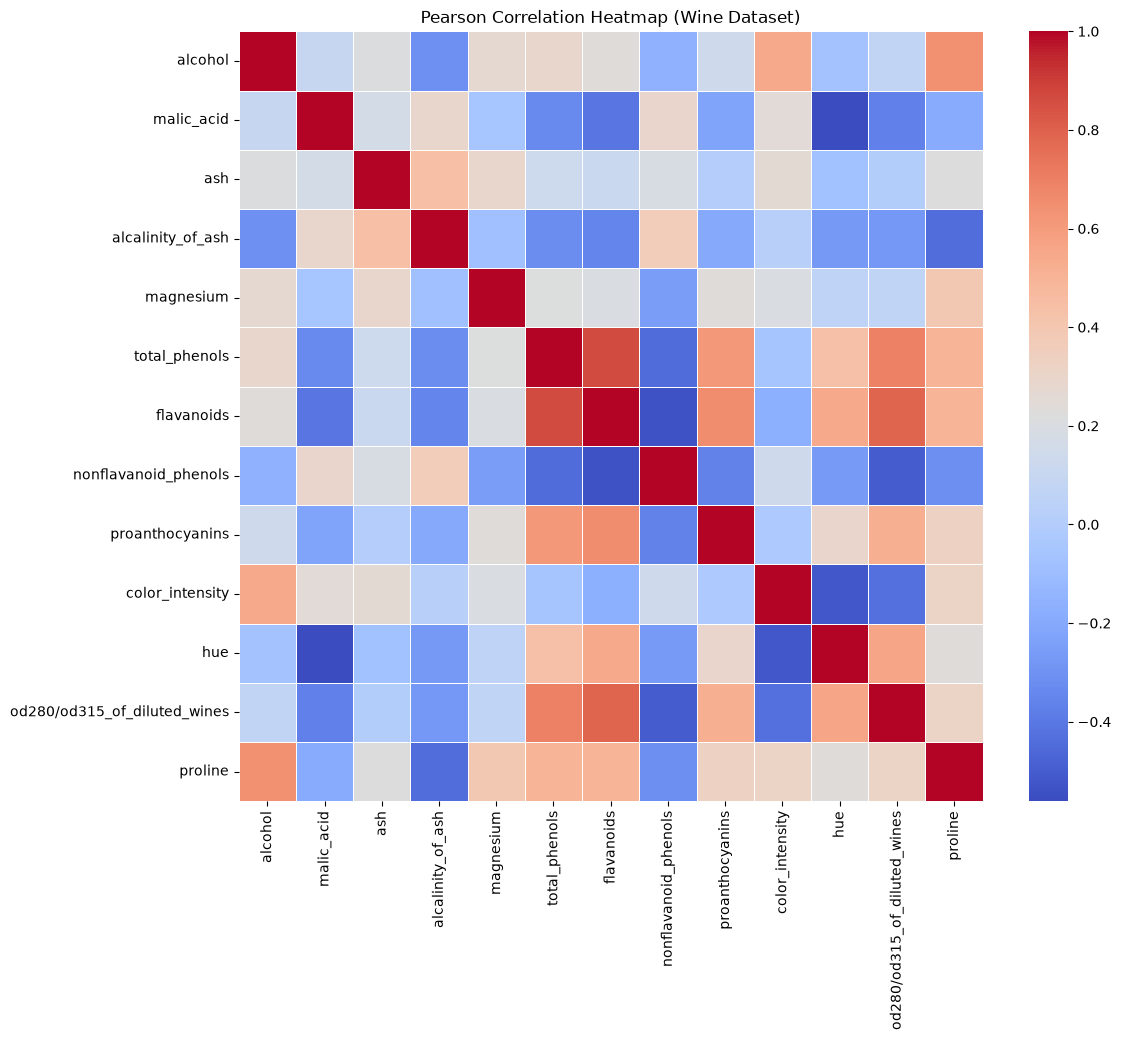

C:\Users\Abdullah\AppData\Local\Temp\ipykernel_26812\290978275.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f'Class {c}' for c in data.target_names])


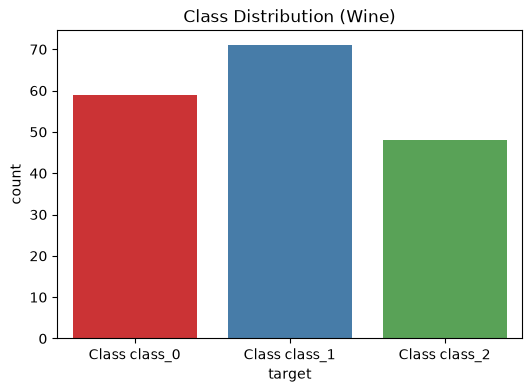

Top 3 Feature Pairs:
flavanoids                    total_phenols    0.864564
od280/od315_of_diluted_wines  flavanoids       0.787194
                              total_phenols    0.699949
dtype: float64


In [5]:
import numpy as np

# --- 3. EDA ---
print("Descriptive Statistics:")
display(X.describe())

# Heatmap
plt.figure(figsize=(12, 10))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Pearson Correlation Heatmap (Wine Dataset)")
plt.show()

# Class Distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, palette="Set1", hue=y, legend=False)
ax.set_xticklabels([f'Class {c}' for c in data.target_names])
plt.title("Class Distribution (Wine)")
plt.show()

# Top 3 Unique Feature Pairs by Absolute Correlation
corr_abs = corr_matrix.abs()
upper_tri = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
top_3 = upper_tri.unstack().sort_values(ascending=False).head(3)
print("Top 3 Feature Pairs:")
print(top_3)

### Section 3: Exploratory Data Analysis
Descriptive statistics verify distinct scales across features (e.g., `proline` ranges in the thousands, while `od280/od315_of_diluted_wines` is below 4). The class distribution is well-balanced across the three cultivar classes. Correlation analysis highlights strong relationships among specific chemical constituents, confirming multicollinearity.

In [6]:
from sklearn.model_selection import train_test_split

# --- 4. DATA SPLITTING ---
# Fix 20% test set once
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

X_train_dict, X_val_dict, y_train_dict, y_val_dict = {}, {}, {}, {}
SEEDS = [42, 52, 62]
split_summary = []

for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed
    )
    X_train_dict[seed], X_val_dict[seed] = X_train, X_val
    y_train_dict[seed], y_val_dict[seed] = y_train, y_val
    
    train_idx, val_idx, test_idx = set(y_train.index), set(y_val.index), set(y_test.index)
    overlap = len(train_idx & val_idx) + len(train_idx & test_idx) + len(val_idx & test_idx)
    total_rows = len(train_idx) + len(val_idx) + len(test_idx)
    
    for subset_name, y_subset in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
        split_summary.append({
            "Seed": seed, 
            "Subset": subset_name, 
            "Total": len(y_subset),
            "Ratio": f"{len(y_subset)/178 * 100:.1f}%",
            "Class 0": y_subset.value_counts().get(0, 0), 
            "Class 1": y_subset.value_counts().get(1, 0),
            "Class 2": y_subset.value_counts().get(2, 0),
            "Overlap": overlap,
            "Sum=178": total_rows == 178
        })

display(pd.DataFrame(split_summary))

,Seed,Subset,Total,Ratio,Class 0,Class 1,Class 2,Overlap,Sum=178
0,42,Train,124,69.7%,41,50,33,0,True
1,42,Val,18,10.1%,6,7,5,0,True
2,42,Test,36,20.2%,12,14,10,0,True
3,52,Train,124,69.7%,41,50,33,0,True
4,52,Val,18,10.1%,6,7,5,0,True
5,52,Test,36,20.2%,12,14,10,0,True
6,62,Train,124,69.7%,41,50,33,0,True
7,62,Val,18,10.1%,6,7,5,0,True
8,62,Test,36,20.2%,12,14,10,0,True


### Section 4: Splitting the Datasets
The Wine dataset is split into training (~70%), validation (~10%), and a fixed test set (20%). Stratification preserves the multi-class distribution across classes 0, 1, and 2. Index checks confirm zero data leakage (overlap = 0) and that subset sizes correctly sum to 178.

In [7]:
from sklearn.preprocessing import StandardScaler

# --- 5. DATA PREPROCESSING (FEATURE SCALING) ---
X_train_scaled_dict = {}
X_val_scaled_dict = {}
scalers_dict = {} 

for seed in SEEDS:
    scaler = StandardScaler()
    
    # CRITICAL: Fit ONLY on training data to prevent data leakage!
    X_train_scaled_dict[seed] = scaler.fit_transform(X_train_dict[seed])
    X_val_scaled_dict[seed] = scaler.transform(X_val_dict[seed])
    scalers_dict[seed] = scaler

print("Original Unscaled Data (Train, Seed 42, First 5 rows):")
display(X_train_dict[42].head(5))

print("\nScaled Data (Train, Seed 42, First 5 rows):")
display(pd.DataFrame(X_train_scaled_dict[42], columns=X.columns, index=X_train_dict[42].index).head(5))

Original Unscaled Data (Train, Seed 42, First 5 rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0



Scaled Data (Train, Seed 42, First 5 rows):


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


### Section 5: Feature Scaling
To prevent data leakage, `StandardScaler` was exclusively fitted to the training set of each respective seed. The learned parameters were then applied to transform both the training and validation subsets. The fixed test set remains entirely isolated and unscaled at this stage. The displayed rows for Seed 42 demonstrate how raw chemical measurements are normalized to a mean of 0 and standard deviation of 1.

In [8]:
# --- 6. PREPARING THE TWO DATA REPRESENTATIONS ---
representations = {
    'unscaled': (X_train_dict, X_val_dict),
    'scaled': (X_train_scaled_dict, X_val_scaled_dict)
}
print("Data representations (scaled and unscaled) are successfully prepared.")

Data representations (scaled and unscaled) are successfully prepared.


### Section 6: Preparing the Two Data Representations
Two distinct data representations were prepared for the modeling phase: unscaled (raw features) and scaled (standardized features). Both representations strictly use the identical row indices allocated during the splitting phase for each seed. No dimensionality reduction was applied.

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# --- 7. TRAINING THE CLASSIFICATION MODELS ---
wine_classifier_runs = []

# Helper function with MULTI-CLASS ROC-AUC specifically for Wine
def evaluate_model_wine(model, X_tr, y_tr, X_v, y_v):
    y_tr_pred = model.predict(X_tr)
    y_v_pred = model.predict(X_v)
    
    # Predict probabilities for ALL 3 classes
    y_v_prob = model.predict_proba(X_v) 
    
    # Train metrics
    tr_acc = accuracy_score(y_tr, y_tr_pred)
    tr_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
    
    # Validation metrics
    v_acc = accuracy_score(y_v, y_v_pred)
    v_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
    v_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
    v_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
    
    # Wine ROC-AUC: multi_class="ovr" and average="macro"
    v_roc = roc_auc_score(y_v, y_v_prob, multi_class='ovr', average='macro')
    
    return tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc

# 7.1 Decision Tree (30 Runs)
depths = [2, 3, 5, 10, None]
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        for d in depths:
            dt = DecisionTreeClassifier(max_depth=d, random_state=seed)
            dt.fit(X_tr, y_tr)
            tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model_wine(dt, X_tr, y_tr, X_v, y_v)
            run_id = f"wine_dt_{rep_name}_depth{d}_s{seed}"
            wine_classifier_runs.append({'Run ID': run_id, 'Dataset': 'Wine', 'Algorithm': 'Decision Tree', 'Representation': rep_name, 'Parameter': f"depth{d}", 'Seed': seed, 'Train Accuracy': tr_acc, 'Train Macro-F1': tr_f1, 'Val Accuracy': v_acc, 'Val Macro-Precision': v_prec, 'Val Macro-Recall': v_rec, 'Val Macro-F1': v_f1, 'Val ROC-AUC': v_roc})

# 7.2 KNN (30 Runs)
neighbors = [1, 3, 5, 7, 11]
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        for k in neighbors:
            knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            knn.fit(X_tr, y_tr)
            tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model_wine(knn, X_tr, y_tr, X_v, y_v)
            run_id = f"wine_knn_{rep_name}_k{k}_s{seed}"
            wine_classifier_runs.append({'Run ID': run_id, 'Dataset': 'Wine', 'Algorithm': 'KNN', 'Representation': rep_name, 'Parameter': f"k{k}", 'Seed': seed, 'Train Accuracy': tr_acc, 'Train Macro-F1': tr_f1, 'Val Accuracy': v_acc, 'Val Macro-Precision': v_prec, 'Val Macro-Recall': v_rec, 'Val Macro-F1': v_f1, 'Val ROC-AUC': v_roc})

# 7.3 Gaussian Naive Bayes (6 Runs)
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        nb = GaussianNB()
        nb.fit(X_tr, y_tr)
        tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model_wine(nb, X_tr, y_tr, X_v, y_v)
        run_id = f"wine_nb_{rep_name}_default_s{seed}"
        wine_classifier_runs.append({'Run ID': run_id, 'Dataset': 'Wine', 'Algorithm': 'Gaussian Naive Bayes', 'Representation': rep_name, 'Parameter': "default", 'Seed': seed, 'Train Accuracy': tr_acc, 'Train Macro-F1': tr_f1, 'Val Accuracy': v_acc, 'Val Macro-Precision': v_prec, 'Val Macro-Recall': v_rec, 'Val Macro-F1': v_f1, 'Val ROC-AUC': v_roc})

print(f"Total Wine runs in master list: {len(wine_classifier_runs)}")

Total Wine runs in master list: 66


### Section 7: Training the Classification Models
A master list was initialized for the Wine dataset to track all 66 classifier experiments (30 Decision Tree, 30 KNN, and 6 Gaussian Naive Bayes runs). 

Since Wine is a multi-class dataset (3 classes), the ROC-AUC evaluation strictly utilized the `multi_class="ovr"` and `average="macro"` configuration alongside `predict_proba`. All other macro-averaged metrics were secured using `zero_division=0`. The required parameter grids were completely exhausted across the three seeds and two representations, relying on the inherent variance of the different train/validation splits for KNN and Naive Bayes, and setting `random_state=seed` for Decision Trees.